# Preparing - Load library `aleph`

## Load library

In [19]:
import os
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.autograd import Variable
import torch_geometric
from torch_geometric.data import HeteroData
from torch_geometric.loader import NeighborLoader
from torch_geometric.nn import HeteroConv, SAGEConv
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from tqdm.notebook import tqdm
from sklearn.metrics.cluster import adjusted_rand_score
import random
from sklearn import metrics
import h5py
import scipy as sp
import scipy.sparse
import scanpy as sc

import sys

import tensorflow.compat.v1 as tf
tf.disable_eager_execution() # Critical for tf.placeholder and Session to work
from keras.layers import Dense, Activation, GaussianNoise

sys.path.append(os.path.abspath('..'))

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 5000)
np.set_printoptions(threshold=np.inf)

In [20]:
BASE_DIR = '../data'
dataset = 'QS_Diaphragm'

MAX_TOPOLOGY_DIM = 1
topo_weight = 80
pretrain_epoch = 5
funetrain_epoch = 10

# 1. Module Code

In [21]:
# --- UTILS ---
class dotdict(dict):
    __getattr__ = dict.get
    __setattr__ = dict.__setitem__
    __delattr__ = dict.__delitem__

def in_ipynb():
    try:
        shell = get_ipython().__class__.__name__
        if shell == "ZMQInteractiveShell": return True
        return False
    except NameError: return False

def smart_tqdm():
    if in_ipynb(): return tqdm.tqdm_notebook
    return tqdm.tqdm

def empty_safe(fn, dtype):
    def _fn(x):
        if x.size: return fn(x)
        return x.astype(dtype)
    return _fn

decode = empty_safe(np.vectorize(lambda _x: _x.decode("utf-8")), str)

# --- LOSS FUNCTIONS ---
MeanAct = lambda x: tf.clip_by_value(tf.exp(x), 1e-5, 1e6)
DispAct = lambda x: tf.clip_by_value(tf.nn.softplus(x), 1e-4, 1e4)

def _nan2zero(x): return tf.where(tf.is_nan(x), tf.zeros_like(x), x)
def _nan2inf(x): return tf.where(tf.is_nan(x), tf.zeros_like(x)+np.inf, x)

def _nelem(x):
    nelem = tf.reduce_sum(tf.cast(~tf.is_nan(x), tf.float32))
    return tf.cast(tf.where(tf.equal(nelem, 0.), 1., nelem), x.dtype)

def _reduce_mean(x):
    nelem = _nelem(x)
    x = _nan2zero(x)
    return tf.divide(tf.reduce_sum(x), nelem)

def neighbor_k_original(k, bank, z):
    result = tf.matmul(z, tf.transpose(bank))
    return tf.nn.top_k(result, k=k)[1]

def distance_k_mask(batchsize, k, bank, z, z_tilde):
    h_index = tf.reshape(neighbor_k_original(k, bank, z), [-1,1])
    h_index = tf.cast(h_index, dtype=tf.int32)
    line = tf.reshape(tf.repeat(np.arange(batchsize), k), [-1,1])
    line = tf.cast(line, dtype=tf.int32)
    index = tf.stack([line, h_index], 1)
    index = tf.reshape(index, [k*batchsize, 2])
    distance = tf.matmul(z_tilde, tf.transpose(bank))
    result = tf.gather_nd(distance, index)
    return tf.reshape(result, [-1, k])

def neighbor_k_loss(batchsize, k, bank, z, z_tilde, temperature):
    bank_normal = bank / tf.reshape(tf.norm(bank, axis=1), [-1, 1])
    z_normal = z / tf.reshape(tf.norm(z, axis=1), [-1, 1])
    z_tilde_normal = z_tilde / tf.reshape(tf.norm(z_tilde, axis=1), [-1, 1])
    numerator = tf.exp(distance_k_mask(batchsize, k, bank_normal, z_normal, z_tilde_normal) / temperature)
    numerator = tf.reduce_sum(numerator, 1) 
    denominator = tf.exp(tf.matmul(z_tilde_normal, tf.transpose(bank_normal)) / temperature) 
    denominator = tf.reduce_sum(denominator, 1) 
    loss = tf.log(numerator / denominator) 
    return -tf.reduce_sum(loss, [0]) / batchsize

def NB(theta, y_true, y_pred, mask=False, debug=False, mean=False):
    eps = 1e-10
    scale_factor = 1.0
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32) * scale_factor
    if mask:
        nelem = _nelem(y_true)
        y_true = _nan2zero(y_true)
    theta = tf.minimum(theta, 1e6)
    t1 = tf.lgamma(theta + eps) + tf.lgamma(y_true + 1.0) - tf.lgamma(y_true + theta + eps)
    t2 = (theta + y_true) * tf.log(1.0 + (y_pred / (theta + eps))) + (y_true * (tf.log(theta + eps) - tf.log(y_pred + eps)))
    final = _nan2inf(t1 + t2)
    if mean:
        if mask: final = tf.divide(tf.reduce_sum(final), nelem)
        else: final = tf.reduce_mean(final)
    return final

def ZINB(pi, theta, y_true, y_pred, ridge_lambda, mean=True, mask=False, debug=False):
    eps = 1e-10
    scale_factor = 1.0
    nb_case = NB(theta, y_true, y_pred, mean=False, debug=debug) - tf.log(1.0 - pi + eps)
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32) * scale_factor
    theta = tf.minimum(theta, 1e6)
    zero_nb = tf.pow(theta / (theta + y_pred + eps), theta)
    zero_case = -tf.log(pi + ((1.0 - pi) * zero_nb) + eps)
    result = tf.where(tf.less(y_true, 1e-8), zero_case, nb_case)
    ridge = ridge_lambda * tf.square(pi)
    result += ridge
    if mean:
        if mask: result = _reduce_mean(result)
        else: result = tf.reduce_mean(result)
    return _nan2inf(result)

def cal_dist(hidden, clusters):
    # Replaced K.sum, K.square, K.expand_dims, K.exp, K.transpose, and K.pow with tf equivalents
    dist1 = tf.reduce_sum(tf.square(tf.expand_dims(hidden, axis=1) - clusters), axis=2)
    temp_dist1 = dist1 - tf.reshape(tf.reduce_min(dist1, axis=1), [-1, 1])
    
    q = tf.exp(-temp_dist1)
    q = tf.transpose(tf.transpose(q) / tf.reduce_sum(q, axis=1))
    q = tf.pow(q, 2)
    q = tf.transpose(tf.transpose(q) / tf.reduce_sum(q, axis=1))
    
    dist2 = dist1 * q
    return dist1, dist2

In [22]:
from sklearn.preprocessing import LabelEncoder
def read_clean(data):
    assert isinstance(data, np.ndarray)
    if data.dtype.type is np.bytes_:
        data = decode(data)
    if data.size == 1:
        data = data.flat[0]
    return data

def dict_from_group(group):
    assert isinstance(group, h5py.Group)
    d = dotdict()
    for key in group:
        if isinstance(group[key], h5py.Group):
            value = dict_from_group(group[key])
        else:
            value = read_clean(group[key][...])
        d[key] = value
    return d
        
def read_data(filename, sparsify=False, skip_exprs=False):
    with h5py.File(filename, "r") as f:
        obs = pd.DataFrame(dict_from_group(f["obs"]), index=decode(f["obs_names"][...]))
        var = pd.DataFrame(dict_from_group(f["var"]), index=decode(f["var_names"][...]))
        uns = dict_from_group(f["uns"])
        if not skip_exprs:
            exprs_handle = f["exprs"]
            if isinstance(exprs_handle, h5py.Group):
                mat = sp.sparse.csr_matrix((exprs_handle["data"][...], exprs_handle["indices"][...],
                                               exprs_handle["indptr"][...]), shape=exprs_handle["shape"][...])
            else:
                mat = exprs_handle[...].astype(np.float32)
                if sparsify:
                    mat = sp.sparse.csr_matrix(mat)
        else:
            mat = sp.sparse.csr_matrix((obs.shape[0], var.shape[0]))
    return mat, obs, var, uns

def prepro(data_path):
    # Modified to accept direct path instead of constructing it from dataname
    mat, obs, var, uns = read_data(data_path, sparsify=False, skip_exprs=False)
    if isinstance(mat, np.ndarray):
        X = np.array(mat)
    else:
        X = np.array(mat.toarray())
    cell_name = np.array(obs["cell_type1"])
    cell_type, cell_label = np.unique(cell_name, return_inverse=True)
    return X, cell_label

def normalize(adata, copy=True, highly_genes=None, filter_min_counts=True, size_factors=True, normalize_input=True, logtrans_input=True):
    if isinstance(adata, sc.AnnData):
        if copy: adata = adata.copy()
    else: raise NotImplementedError

    if filter_min_counts:
        sc.pp.filter_genes(adata, min_counts=1)
        sc.pp.filter_cells(adata, min_counts=1)
    
    adata.raw = adata.copy() if (size_factors or normalize_input or logtrans_input) else adata
    
    if size_factors:
        sc.pp.normalize_total(adata)
        # scNAME expects size_factors to be computed this way
        adata.obs['size_factors'] = adata.obs.n_counts / np.median(adata.obs.n_counts)
    else:
        adata.obs['size_factors'] = 1.0
        
    if logtrans_input: sc.pp.log1p(adata)
        
    if highly_genes != None:
        sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5, n_top_genes=highly_genes, subset=True)
        
    if normalize_input: sc.pp.scale(adata)
        
    return adata

In [23]:
import numpy as np
import functools
import tensorflow.compat.v1 as tf
from keras.layers import Dense, Activation, GaussianNoise
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# ==========================================
# 1. TOPOLOGICAL LOSS UTILITIES
# ==========================================
def py_get_vr_indices(dist_matrix_np, max_dimension=1):
    """NumPy wrapper for aleph VR complex."""
    from aleph import vietoris_rips_from_matrix
    pairs = vietoris_rips_from_matrix(dist_matrix_np, max_dimension=max_dimension)
    edge_pairs = []

    def traceback_index(edge_distance):
        indices = np.where(np.isclose(dist_matrix_np, edge_distance, atol=1e-6))
        if len(indices[0]) == 0: return -1, -1 
        return indices[0][0], indices[1][0]

    if len(pairs) > 0:
        for point in pairs[0]:
            if point.y != float('inf'):
                i, j = traceback_index(point.y)
                if i != -1 and j != -1: edge_pairs.append((i, j))

    for dim in range(1, len(pairs)):
        pairs[dim].removeDiagonal()
        for point in pairs[dim]:
            i_x, j_x = traceback_index(point.x)
            if i_x != -1 and j_x != -1: edge_pairs.append((i_x, j_x))
            if point.y != float('inf'):
                i_y, j_y = traceback_index(point.y)
                if i_y != -1 and j_y != -1: edge_pairs.append((i_y, j_y))

    if len(edge_pairs) == 0:
        return np.zeros((0, 2), dtype=np.int64)
    return np.array(edge_pairs, dtype=np.int64)

def tf_euclidean_distance(tensor):
    """Computes pairwise euclidean distance matrix in TF."""
    sq = tf.reduce_sum(tf.square(tensor), axis=1, keepdims=True)
    d2 = sq - 2.0 * tf.matmul(tensor, tensor, transpose_b=True) + tf.transpose(sq)
    return tf.sqrt(tf.maximum(d2, 1e-12))

def tf_topological_loss(X_batch, Z_batch, max_dim=1):
    """Computes the topological consistency loss in TensorFlow."""
    batch_size_float = tf.cast(tf.shape(X_batch)[0], tf.float32)
    dim_X = tf.cast(tf.reduce_prod(tf.shape(X_batch)[1:]), tf.float32)
    dim_Z = tf.cast(tf.reduce_prod(tf.shape(Z_batch)[1:]), tf.float32)
    
    X_norm = tf.nn.l2_normalize(X_batch, axis=0) / dim_X
    Z_norm = tf.nn.l2_normalize(Z_batch, axis=0) / dim_Z

    mX = tf_euclidean_distance(X_norm)
    mZ = tf_euclidean_distance(Z_norm)

    vr_func = functools.partial(py_get_vr_indices, max_dimension=max_dim)
    y_X_indices = tf.py_func(vr_func, [mX], tf.int64)
    y_Z_indices = tf.py_func(vr_func, [mZ], tf.int64)

    y_X_indices.set_shape([None, 2])
    y_Z_indices.set_shape([None, 2])

    mX_yX = tf.gather_nd(mX, y_X_indices)
    mX_yZ = tf.gather_nd(mX, y_Z_indices)
    mZ_yX = tf.gather_nd(mZ, y_X_indices)
    mZ_yZ = tf.gather_nd(mZ, y_Z_indices)

    loss_X = tf.reduce_sum(tf.square(mX_yX - mX_yZ)) * 0.5
    loss_Z = tf.reduce_sum(tf.square(mZ_yZ - mZ_yX))
    
    return (loss_X + loss_Z) / batch_size_float * dim_Z

# ==========================================
# 2. scNAME NETWORK GENERATORS
# ==========================================
def mask_generator(p_m, x):
    return np.random.binomial(1, p_m, x.shape)

def pretext_generator(m, x):
    no, dim = x.shape
    x_bar = np.zeros([no, dim])
    for i in range(dim):
        idx = np.random.permutation(no)
        x_bar[:, i] = x[idx, i]
    x_tilde = x * (1 - m) + x_bar * m
    m_new = 1 * (x != x_tilde)
    return m_new, x_tilde

# ==========================================
# 3. AUTOENCODER CLASS
# ==========================================
class autoencoder(object):
    def __init__(self, dataname, n, batch_size, k, temperature, dims, cluster_num, alpha, beta, gamma, learning_rate, noise_sd=1.5, init='glorot_uniform', act='relu', use_topo=False, topo_weight=0.05):
        self.dataname = dataname
        self.n = n
        self.batch_size = batch_size
        self.k = k
        self.temperature = temperature
        self.dims = dims
        self.cluster_num = cluster_num
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.learning_rate = learning_rate
        self.noise_sd = noise_sd
        self.init = init
        self.act = act
        self.n_stacks = len(self.dims) - 1
        
        # New Topological Toggles
        self.use_topo = use_topo
        self.topo_weight = topo_weight
        
        self.sf_layer = tf.placeholder(dtype=tf.float32, shape=(None, 1))
        self.x_origin = tf.placeholder(dtype=tf.float32, shape=(None, self.dims[0]))
        self.x_count = tf.placeholder(dtype=tf.float32, shape=(None, self.dims[0]))
        self.x_tilde = tf.placeholder(dtype=tf.float32, shape=(None, self.dims[0]))
        self.batch = tf.placeholder(dtype=tf.int32, shape=(None, 1))
        self.m = tf.placeholder(dtype=tf.float32, shape=(None, self.dims[0]))
        
        self.bank = tf.get_variable(name=self.dataname + "/bank", dtype=tf.float32, initializer=tf.zeros([self.n, self.dims[-1]]), trainable=False)
        self.clusters = tf.get_variable(name=self.dataname + "/clusters_rep", shape=[self.cluster_num, self.dims[-1]], dtype=tf.float32, initializer=tf.glorot_uniform_initializer())

        def encoder(x_input, dims, init, act, n_stacks):
            h = x_input
            h = GaussianNoise(self.noise_sd, name='input_noise')(h)  
            for i in range(n_stacks - 1):
                h = Dense(units=dims[i + 1], kernel_initializer=init, name='encoder_%d' % i)(h) 
                h = GaussianNoise(self.noise_sd, name='noise_%d' % i)(h)
                h = Activation(act)(h) 
            latent = Dense(units=dims[-1], kernel_initializer=init, name='encoder_hidden')(h)
            h = latent
            for i in range(n_stacks - 1, 0, -1):
                h = Dense(units=dims[i], activation=act, kernel_initializer=init, name='decoder_%d' % i)(h)
            mask_estimator = Dense(units=dims[0], activation='sigmoid', kernel_initializer=init, name='mask_estimator')(h)
            pi = Dense(units=dims[0], activation='sigmoid', kernel_initializer=init, name='pi')(h)
            disp = Dense(units=dims[0], activation=DispAct, kernel_initializer=init, name='dispersion')(h)
            mean = Dense(units=dims[0], activation=MeanAct, kernel_initializer=init, name='mean')(h)
            return latent, mask_estimator, pi, disp, mean
       
        self.encoder_x_tilde, self.mask_estimator, _, _, _ = encoder(self.x_tilde, self.dims, self.init, self.act, self.n_stacks)
        self.encoder_x, _, self.pi, self.disp, self.mean = encoder(self.x_origin, self.dims, self.init, self.act, self.n_stacks)
        self.output = self.mean * tf.matmul(self.sf_layer, tf.ones((1, self.mean.get_shape()[1]), dtype=tf.float32))
        
        self.bank = tf.scatter_nd_update(self.bank, self.batch, self.encoder_x)
        self.likelihood_loss = ZINB(self.pi, self.disp, self.x_count, self.output, ridge_lambda=1.0)
        self.mask_loss = tf.reduce_mean(tf.keras.losses.binary_crossentropy(self.m, self.mask_estimator), 0)
        self.latent_idx, _ = cal_dist(self.bank, self.clusters)
        self.neighbor_loss = neighbor_k_loss(self.batch_size, self.k, self.bank, self.encoder_x, self.encoder_x_tilde, self.temperature)
        self.latent_dist1, self.latent_dist2 = cal_dist(self.encoder_x, self.clusters)
        self.kmeans_loss = tf.reduce_mean(tf.reduce_sum(self.latent_dist2, axis=1))
        
        # Base scNAME Loss
        self.base_loss = self.likelihood_loss + self.alpha*self.mask_loss + self.beta*self.neighbor_loss + self.gamma*self.kmeans_loss
        
        # Add Topological Loss if enabled
        if self.use_topo:
            self.topo_loss = tf_topological_loss(self.x_origin, self.encoder_x)
            self.total_loss = self.base_loss + (self.topo_weight * self.topo_loss)
        else:
            self.topo_loss = tf.constant(0.0) 
            self.total_loss = self.base_loss

        self.optimizer = tf.train.AdamOptimizer(self.learning_rate)
        self.pretrain_op = self.optimizer.minimize(self.likelihood_loss + self.alpha*self.mask_loss)
        self.train_op = self.optimizer.minimize(self.total_loss)

    def encode(self, X_data, size_factor=None, batch_size=256):
        """
        Encode input matrix X_data to latent embeddings and return as numpy ndarray.

        - X_data: numpy array of shape (n_samples, n_features) matching model input dims[0].
        - size_factor: optional numpy array of shape (n_samples, 1). If None, will use ones.
        - batch_size: inference batch size.

        Requires an active TensorFlow v1 Session stored as self.sess (created by pretrain/funetrain).
        """
        import numpy as _np

        if not hasattr(self, 'sess') or self.sess is None:
            raise RuntimeError("No active TensorFlow session found on the model. "
                               "Call pretrain(...) or keep the session open (do not call funetrain() which closes the session), "
                               "or modify funetrain() to not close the session before calling encode().")

        X = _np.asarray(X_data, dtype=_np.float32)
        n_samples = X.shape[0]

        if size_factor is None:
            sf = _np.ones((n_samples, 1), dtype=_np.float32)
        else:
            sf = _np.asarray(size_factor, dtype=_np.float32)
            if sf.shape[0] != n_samples:
                raise ValueError("size_factor must have same number of rows as X_data")

        embeddings = []
        for i in range(0, n_samples, batch_size):
            x_batch = X[i : i + batch_size]
            sf_batch = sf[i : i + batch_size]
            feed = {
                self.x_origin: x_batch,
                self.sf_layer: sf_batch
            }
            # Run encoder_x to get latent representation
            batch_latent = self.sess.run(self.encoder_x, feed_dict=feed)
            embeddings.append(batch_latent)

        return _np.vstack(embeddings)

    def pretrain(self, X, count_X, p_m, size_factor, batch_size, pretrain_epoch):
        print("Begin pretraining...")
        init = tf.group(tf.global_variables_initializer(), tf.local_variables_initializer())
        config_ = tf.ConfigProto()
        config_.gpu_options.allow_growth = True
        config_.allow_soft_placement = True
        self.sess = tf.Session(config=config_)
        self.sess.run(init)
        
        pre_index = 0
        for ite in range(pretrain_epoch):
            while True:
                if (pre_index + 1) * batch_size > X.shape[0]:
                    last_index = np.array(list(range(pre_index * batch_size, X.shape[0])) + list(range((pre_index + 1) * batch_size - X.shape[0])))
                    last_index_new = last_index.reshape([-1, 1])
                    x_batch = X[last_index]
                    m_batch = mask_generator(p_m, x_batch)
                    m_batch_new, x_tilde_batch = pretext_generator(m_batch, x_batch)

                    _, mask_loss, likelihood_loss, latent, bank = self.sess.run(
                        [self.pretrain_op, self.mask_loss, self.likelihood_loss, self.encoder_x, self.bank],
                        feed_dict={self.x_origin: x_batch, self.x_count: count_X[last_index], self.batch: last_index_new,
                                   self.m : m_batch_new, self.x_tilde: x_tilde_batch, self.sf_layer: size_factor[last_index]})
                    self.bank_current = bank
                    if ite % 10 == 0:
                       print(f'Epoch: {ite}/{pretrain_epoch}, Iteration: {pre_index}, Likelihood loss: {np.round(likelihood_loss, 4)}, Mask loss: {np.round(mask_loss, 4)}')
                    pre_index = 0
                    break
                else:
                    batch_index = np.arange(pre_index * batch_size, (pre_index + 1) * batch_size)
                    batch_index_new = batch_index.reshape([-1,1])
                    x_batch = X[batch_index]
                    m_batch = mask_generator(p_m, x_batch)
                    m_batch_new, x_tilde_batch = pretext_generator(m_batch, x_batch)
                    
                    _, mask_loss, likelihood_loss, latent, bank = self.sess.run(
                        [self.pretrain_op, self.mask_loss, self.likelihood_loss, self.encoder_x, self.bank],
                        feed_dict={self.x_origin: x_batch, self.x_count: count_X[batch_index], self.batch: batch_index_new,
                                   self.m : m_batch_new, self.x_tilde: x_tilde_batch, self.sf_layer: size_factor[batch_index]})
                    self.bank_current = bank              
                    pre_index += 1

    def funetrain(self, dataname, X, Y, count_X, p_m, size_factor, batch_size, funetrain_epoch, update_epoch, error):
        kmeans = KMeans(n_clusters=self.cluster_num, init="k-means++", n_init=10)
        self.kmeans_pred = kmeans.fit_predict(self.bank_current)
        self.last_pred = np.copy(self.kmeans_pred)
        self.sess.run(tf.assign(self.clusters, kmeans.cluster_centers_))
        self.kmeans_ARI = np.around(adjusted_rand_score(Y, self.kmeans_pred), 5)
        self.Y_pred_best = self.kmeans_pred
        print("Initial KMeans ARI:", self.kmeans_ARI)
        print("Begin fine-tuning...")

        fune_index = 0
        for i in range(1, funetrain_epoch + 1):
            while True:
                if (fune_index + 1) * batch_size > X.shape[0]:
                    last_index = np.array(list(range(fune_index * batch_size, X.shape[0])) + list(range((fune_index + 1) * batch_size - X.shape[0])))
                    last_index_new = last_index.reshape([-1, 1])
                    x_batch = X[last_index]
                    m_batch = mask_generator(p_m, x_batch)
                    m_batch_new, x_tilde_batch = pretext_generator(m_batch, x_batch)
                    
                    fetches = [self.train_op, self.base_loss, self.topo_loss, self.total_loss, self.latent_idx, self.encoder_x, self.bank]
                    feed = {self.x_origin: x_batch, self.x_count: count_X[last_index], self.batch: last_index_new,
                            self.m: m_batch_new, self.x_tilde: x_tilde_batch, self.sf_layer: size_factor[last_index]}
                    
                    _, base_l, topo_l, total_l, latent_idx_cur, latent, bank = self.sess.run(fetches, feed_dict=feed)
               
                    self.Y_pred = np.argmin(latent_idx_cur, axis=1)
              
                    if (i - 1) % 10 == 0:
                        self.ARI = np.around(adjusted_rand_score(Y, self.Y_pred), 5)
                        log_str = f"Epoch {i-1}/{funetrain_epoch} | Base Loss: {base_l:.4f}"
                        if self.use_topo:
                            log_str += f" | Topo Loss: {topo_l:.4f}"
                        log_str += f" | Total Loss: {total_l:.4f} | ARI: {self.ARI}"
                        print(log_str)
                        
                    fune_index = 0
                    break
                else:
                    batch_index = np.arange(fune_index * batch_size, (fune_index + 1) * batch_size)
                    batch_index_new = batch_index.reshape([-1, 1])
                    x_batch = X[batch_index]
                    m_batch = mask_generator(p_m, x_batch)
                    m_batch_new, x_tilde_batch = pretext_generator(m_batch, x_batch)
                    
                    fetches = [self.train_op, self.base_loss, self.topo_loss, self.total_loss, self.latent_idx, self.bank, self.encoder_x]
                    feed = {self.x_origin: x_batch, self.x_count: count_X[batch_index], self.batch: batch_index_new,
                            self.m: m_batch_new, self.x_tilde: x_tilde_batch, self.sf_layer: size_factor[batch_index]}
                    
                    _, base_l, topo_l, total_l, latent_idx_cur, bank, latent = self.sess.run(fetches, feed_dict=feed)
                  
                    self.Y_pred = np.argmin(latent_idx_cur, axis=1)
                    fune_index += 1
                    
            if i % update_epoch == 0:
                current_error = np.sum(self.Y_pred != self.last_pred) / len(self.last_pred)
                # print("current_error:", current_error)
                if current_error < error:
                    print(f"Early stopping at epoch {i} with error {current_error:.4f} < {error}")
                    break
                else:
                    self.last_pred = self.Y_pred
                    
        # self.sess.close()
        return self.Y_pred

# 2. Train Model

In [24]:
p_m = 0.3
k = 10
temperature = 0.7
dims = [256, 64, 32]
highly_genes = 1000
alpha = 1.0
beta = 0.1
gamma = 0.1
learning_rate = 0.0001
batch_size = 128
update_epoch = 50
noise_sd = 1.0
error = 0.001

# Topological Loss Settings
use_topo_loss = True
n_clusters = None # Will be set dynamically

In [25]:
import h5py
from utils.evaluation import cluster_acc

torch.manual_seed(1111)
np.random.seed(1111)

# 2. Dynamically load data and determine n_clusters
data_path = f"{BASE_DIR}/{dataset}.h5"
print("Reading labels to determine the exact number of clusters...")

with h5py.File(data_path, 'r') as inputFile:
    Y_temp = np.array(inputFile['Y'])
    if Y_temp.dtype != "int64":
        Y_temp = LabelEncoder().fit_transform(Y_temp)
    n_clusters = len(set(Y_temp))
    print(f"Successfully detected and assigned n_clusters = {n_clusters}")
    
    # ASSUMPTION: Your expression matrix is stored under the key 'X'. 
    # Change 'X' below if it is named differently in your .h5 file.
    X_temp = np.array(inputFile['X'])

X = np.ceil(X_temp).astype(np.float32) 
count_X = np.ceil(X_temp).astype(int) 
Y = Y_temp

# Shuffle the dataset
shuffle_ix = np.random.permutation(np.arange(len(X)))
X = X[shuffle_ix]
Y = Y[shuffle_ix]
count_X = count_X[shuffle_ix]

# 3. Create AnnData object just to run the required scNAME normalizations
print("Running Scanpy normalization to get size factors...")
adata = sc.AnnData(X)
adata.obs['Group'] = Y
adata = normalize(adata, copy=True, highly_genes=highly_genes, size_factors=True, normalize_input=True, logtrans_input=True)

X = adata.X.astype(np.float32)
Y = np.array(adata.obs["Group"])
n = X.shape[0]

# Filter count_X to match the highly variable genes selected by scanpy
high_variable = np.array(adata.var.highly_variable.index, dtype=np.int32) 
count_X = count_X[:, high_variable]
size_factor = np.array(adata.obs.size_factors).reshape(-1, 1).astype(np.float32)

# Update dims list for network architecture
dims_list = dims.copy()
dims_list.insert(0, highly_genes)


tf.reset_default_graph() 

# Instantiate the model with the topological flags
model_1 = autoencoder(
    dataset, n, batch_size, k, temperature,
    dims_list, n_clusters, alpha, beta, gamma, 
    learning_rate, noise_sd,
    use_topo=False, 
    topo_weight=0
)

# Pretrain and Fine-tune
model_1.pretrain(X, count_X, p_m, size_factor, batch_size, pretrain_epoch)
model_1.funetrain(dataset, X, Y, count_X, p_m, size_factor, batch_size, funetrain_epoch, update_epoch, error)

acc_1 = np.around(cluster_acc(Y, model_1.Y_pred), 4)
ari_1 = np.around(adjusted_rand_score(Y, model_1.Y_pred), 4)
nmi_1 = np.around(normalized_mutual_info_score(Y, model_1.Y_pred), 4)


# 4. With Topo Loss
tf.reset_default_graph() 

# Instantiate the model with the topological flags
model_2 = autoencoder(
    dataset, n, batch_size, k, temperature,
    dims_list, n_clusters, alpha, beta, gamma, 
    learning_rate, noise_sd,
    use_topo=use_topo_loss, 
    topo_weight=topo_weight
)

# Pretrain and Fine-tune
model_2.pretrain(X, count_X, p_m, size_factor, batch_size, pretrain_epoch)
model_2.funetrain(dataset, X, Y, count_X, p_m, size_factor, batch_size, funetrain_epoch, update_epoch, error)

acc_2 = np.around(cluster_acc(Y, model_2.Y_pred), 4)
ari_2 = np.around(adjusted_rand_score(Y, model_2.Y_pred), 4)
nmi_2 = np.around(normalized_mutual_info_score(Y, model_2.Y_pred), 4)

print(f"Results without Topological Loss: ACC={acc_1}, ARI={ari_1}, NMI={nmi_1}")
print(f"Results with Topological Loss: ACC={acc_2}, ARI={ari_2}, NMI={nmi_2}")

Reading labels to determine the exact number of clusters...
Successfully detected and assigned n_clusters = 5
Running Scanpy normalization to get size factors...
Begin pretraining...
Epoch: 0/5, Iteration: 6, Likelihood loss: 19.281099319458008, Mask loss: 0.683899998664856
Initial KMeans ARI: 0.41532
Begin fine-tuning...
Epoch 0/10 | Base Loss: 13.1935 | Total Loss: 13.1935 | ARI: 0.49564
Begin pretraining...
Epoch: 0/5, Iteration: 6, Likelihood loss: 19.717199325561523, Mask loss: 0.6866999864578247
Initial KMeans ARI: 0.72519
Begin fine-tuning...
Epoch 0/10 | Base Loss: 15.4242 | Topo Loss: 0.0007 | Total Loss: 15.4780 | ARI: 0.68408
Results without Topological Loss: ACC=0.5862, ARI=0.3556, NMI=0.4633
Results with Topological Loss: ACC=0.6701, ARI=0.4272, NMI=0.5407


## Robustness Evaluation

### Prepare util functions

In [31]:
from sklearn.preprocessing import normalize as sklearn_normalize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def predict_clusters(embeddings, num_clusters):
    Z = sklearn_normalize(embeddings, norm='l2')
    kmeans = KMeans(n_init=num_clusters, init="k-means++", random_state=0)
    pred = kmeans.fit_predict(Z)
    return pred

def noise_evaluation(Z_eval_1, Z_eval_2, num_clusters):
    # 1. Convert TensorFlow Tensors to standard NumPy arrays
    # This works as long as the code is run eagerly (not inside a @tf.function graph)
    if isinstance(Z_eval_1, tf.Tensor):
        Z_1 = Z_eval_1.numpy()
    else:
        Z_1 = np.array(Z_eval_1)
        
    if isinstance(Z_eval_2, tf.Tensor):
        Z_2 = Z_eval_2.numpy()
    else:
        Z_2 = np.array(Z_eval_2)

    # 2. Scikit-Learn Normalization
    Z_1 = sklearn_normalize(Z_1, norm='l2')
    Z_2 = sklearn_normalize(Z_2, norm='l2')

    # 3. KMeans Clustering
    # Note: Passed num_clusters to n_clusters, and explicitly set n_init to 10
    pred_1 = predict_clusters(Z_1, num_clusters)
    pred_2 = predict_clusters(Z_2, num_clusters)

    # 4. Calculate accuracy
    acc = cluster_acc(pred_1, pred_2)
    return float(acc)

# Get the latent representation from model_1 by training for 0 epochs (just to get the embeddings)
baseline_embedding_1 = model_1.encode(X, size_factor=size_factor, batch_size=batch_size)
baseline_embedding_2 = model_2.encode(X, size_factor=size_factor, batch_size=batch_size)

### A. Dropout event in gene expression matrix

Dropout Noise Level: 0.00 | Model 1 perturbation: 1.0000 | Model 2 perturbation: 1.0000
Dropout Noise Level: 0.05 | Model 1 perturbation: 0.6115 | Model 2 perturbation: 0.7092
Dropout Noise Level: 0.10 | Model 1 perturbation: 0.5241 | Model 2 perturbation: 0.6356
Dropout Noise Level: 0.15 | Model 1 perturbation: 0.5046 | Model 2 perturbation: 0.5655
Dropout Noise Level: 0.20 | Model 1 perturbation: 0.4517 | Model 2 perturbation: 0.4023
Dropout Noise Level: 0.25 | Model 1 perturbation: 0.4287 | Model 2 perturbation: 0.3989
Dropout Noise Level: 0.30 | Model 1 perturbation: 0.3655 | Model 2 perturbation: 0.3138
Dropout Noise Level: 0.35 | Model 1 perturbation: 0.2897 | Model 2 perturbation: 0.2678
Dropout Noise Level: 0.40 | Model 1 perturbation: 0.2736 | Model 2 perturbation: 0.2448
Dropout Noise Level: 0.45 | Model 1 perturbation: 0.2230 | Model 2 perturbation: 0.2264


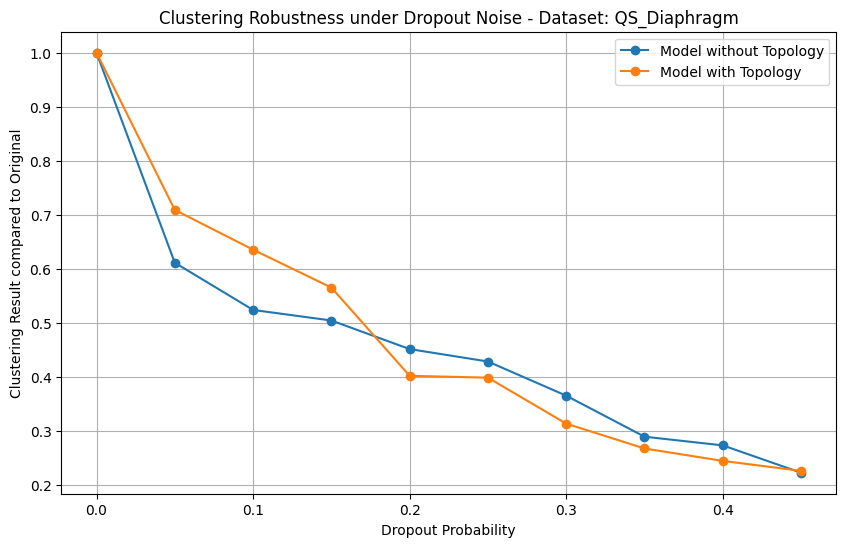

In [33]:
from utils.perturbation import dropout_event

# Testing with dropout_event first
drop_prob = np.arange(0, 0.5, 0.05)
tf.config.run_functions_eagerly(True) 

acc_scores_1 = []
acc_scores_2 = []

def dropout_event(X_data: np.ndarray, drop_prob: float):
    """Randomly zero out individual elements of X with probability drop_prob."""
    # Create a mask of the exact same shape as the input data
    drop_mask = np.random.rand(*X_data.shape) < drop_prob
    X_data[drop_mask] = 0 # Applies mask element-wise
    return X_data

for prob in drop_prob:
    x_noisy = dropout_event(X, prob)

    embedding_1 = model_1.encode(x_noisy, size_factor=size_factor, batch_size=batch_size)
    embedding_2 = model_2.encode(x_noisy, size_factor=size_factor, batch_size=batch_size)

    acc_scores_1.append(noise_evaluation(embedding_1, baseline_embedding_1, n_clusters))
    acc_scores_2.append(noise_evaluation(embedding_2, baseline_embedding_2, n_clusters))
    print(f"Dropout Noise Level: {prob:.2f} | Model 1 perturbation: {acc_scores_1[-1]:.4f} | Model 2 perturbation: {acc_scores_2[-1]:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(drop_prob, acc_scores_1, marker='o', label='Model without Topology')
plt.plot(drop_prob, acc_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Dropout Probability')
plt.ylabel('Clustering Result compared to Original')

plt.title(f'Clustering Robustness under Dropout Noise - Dataset: {dataset}')

plt.legend()
plt.grid()
plt.show()

## B. Testing robustness with Gaussian noise in `X_data`

Gaussian Noise Level: 0.00 | Model 1 perturbation: 0.2230 | Model 2 perturbation: 0.2092
Gaussian Noise Level: 0.02 | Model 1 perturbation: 0.1931 | Model 2 perturbation: 0.2046
Gaussian Noise Level: 0.04 | Model 1 perturbation: 0.1782 | Model 2 perturbation: 0.1874
Gaussian Noise Level: 0.06 | Model 1 perturbation: 0.1828 | Model 2 perturbation: 0.1839
Gaussian Noise Level: 0.08 | Model 1 perturbation: 0.1851 | Model 2 perturbation: 0.1828
Gaussian Noise Level: 0.10 | Model 1 perturbation: 0.1931 | Model 2 perturbation: 0.1816
Gaussian Noise Level: 0.12 | Model 1 perturbation: 0.1954 | Model 2 perturbation: 0.1874
Gaussian Noise Level: 0.14 | Model 1 perturbation: 0.1920 | Model 2 perturbation: 0.1908
Gaussian Noise Level: 0.16 | Model 1 perturbation: 0.1977 | Model 2 perturbation: 0.1908
Gaussian Noise Level: 0.18 | Model 1 perturbation: 0.2011 | Model 2 perturbation: 0.1897
Gaussian Noise Level: 0.20 | Model 1 perturbation: 0.1943 | Model 2 perturbation: 0.2023
Gaussian Noise Level:

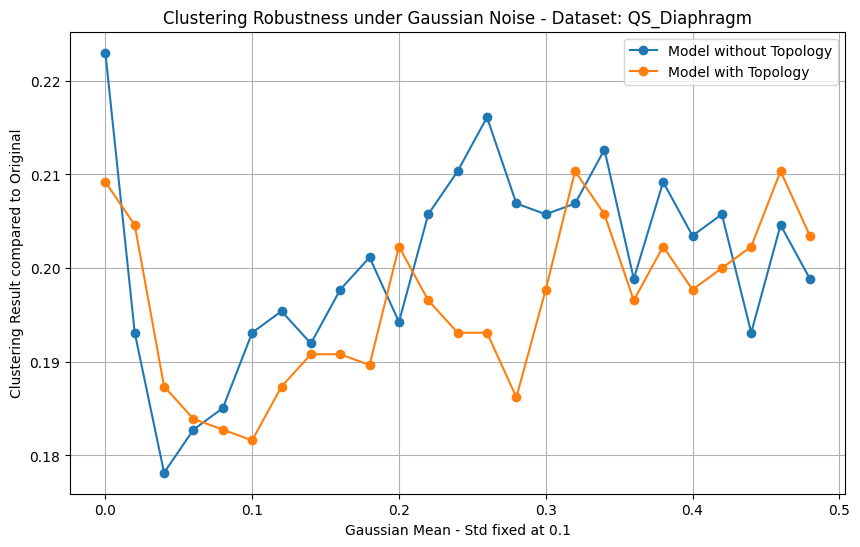

In [38]:
def gaussian_noise_event(X_data: np.ndarray, mean: float = 0.0, std: float = 0.1):
    """Add Gaussian noise to X_data."""
    noise = np.random.randn(*X_data.shape) * std + mean
    return X_data + noise

# Testing with dropout_event first
gaussian_mean = np.arange(0, 0.5, 0.02)

acc_scores_1 = []
acc_scores_2 = []

for mean in gaussian_mean:
    x_noisy = gaussian_noise_event(X, mean, std=0.1)

    embedding_1 = model_1.encode(x_noisy, size_factor=size_factor, batch_size=batch_size)
    embedding_2 = model_2.encode(x_noisy, size_factor=size_factor, batch_size=batch_size)

    acc_scores_1.append(noise_evaluation(embedding_1, baseline_embedding_1, n_clusters))
    acc_scores_2.append(noise_evaluation(embedding_2, baseline_embedding_2, n_clusters))
    print(f"Gaussian Noise Level: {mean:.2f} | Model 1 perturbation: {acc_scores_1[-1]:.4f} | Model 2 perturbation: {acc_scores_2[-1]:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(gaussian_mean, acc_scores_1, marker='o', label='Model without Topology')
plt.plot(gaussian_mean, acc_scores_2, marker='o', label='Model with Topology')
plt.xlabel('Gaussian Mean - Std fixed at 0.1')
plt.ylabel('Clustering Result compared to Original')

plt.title(f'Clustering Robustness under Gaussian Noise - Dataset: {dataset}')
plt.legend()
plt.grid()
plt.show()